# Day 6: Inference and model comparison

Two models predict sentiment for the same tweets:

- **baseline** (day 4): frozen DistilBERT turns a tweet into a CLS vector, a logistic regression classifies the vector;
- **fine-tuned** (day 5): DistilBERT with a classification head, all weights trained on the tweets.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split

from itg_transformers.config import (
    BASELINE_PATH,
    EMBEDDINGS_DIR,
    FIGURES_DIR,
    FINE_TUNED_DIR,
    LABELS,
    MODEL_NAME,
    RESULTS_DIR,
)
from itg_transformers.data import clean_text, load_split
from itg_transformers.embeddings import load_model, pick_device
from itg_transformers.finetuning import load_classifier
from itg_transformers.inference import (
    FrozenEncoderVectorizer,
    predict_baseline,
    predict_fine_tuned,
)
from itg_transformers.tokenization import load_tokenizer

## 1. Loading the models

### Fine-tuned model

Saved on day 5 to `models/fine_tuned_model/` together with its tokenizer. `load_classifier` is `AutoModelForSequenceClassification.from_pretrained`, and `from_pretrained` already returns the model in eval mode; `eval()` is called anyway, as the task asks. `load_tokenizer` (day 1) is `AutoTokenizer.from_pretrained`, here pointed at the saved folder.

In [2]:
device = pick_device()
model_ft = load_classifier(str(FINE_TUNED_DIR))
model_ft.to(device)  # ty: ignore[invalid-argument-type]
model_ft.eval()
tokenizer = load_tokenizer(str(FINE_TUNED_DIR))

print(f"Fine-tuned: {type(model_ft).__name__} on {model_ft.device}")
print(f"Labels: {model_ft.config.id2label}")
print(
    f"Tokenizer: {type(tokenizer).__name__}, vocabulary {tokenizer.vocab_size}"
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Fine-tuned: DistilBertForSequenceClassification on mps:0
Labels: {0: 'negative', 1: 'neutral', 2: 'positive'}
Tokenizer: BertTokenizer, vocabulary 30522


### Baseline model

The task expects `baseline_model.pkl` and `vectorizer.pkl` from day 4, a TF-IDF style baseline. Ours differs in two ways:

1. Day 4 did not save the classifier, its task did not ask for it. Refitting is cheap: the CLS embeddings are cached in `data/embeddings/`, so the logistic regression is fitted again here and saved with joblib.
2. The role of the vectorizer is played by the frozen DistilBERT that turns texts into CLS vectors. Its weights are the public `distilbert-base-uncased`, so there is nothing of ours to pickle; section 3 wraps it into an object with the same `transform` method as a vectorizer.

The regression is fitted on exactly the 80% of train the fine-tuned model was trained on (day 4 section 4 / day 5 section 2), so both models have seen the same tweets. It must reproduce the day 4 score on the remaining 20%.

In [3]:
train = load_split("train")
cls_train = np.load(EMBEDDINGS_DIR / f"{MODEL_NAME}_cls_train.npy")
rows_train, rows_val = train_test_split(
    np.arange(len(train)),
    test_size=0.2,
    random_state=42,
    stratify=train["label"],
)
labels = train["label"].to_numpy()

if BASELINE_PATH.exists():
    print(f"Using the saved {BASELINE_PATH.name}")
else:
    regression = LogisticRegression(max_iter=1000)
    regression.fit(cls_train[rows_train], labels[rows_train])
    joblib.dump(regression, BASELINE_PATH)
    print(f"Saved {BASELINE_PATH.relative_to(BASELINE_PATH.parents[1])}")

baseline_model = joblib.load(BASELINE_PATH)
check = f1_score(
    labels[rows_val],
    baseline_model.predict(cls_train[rows_val]),
    average="macro",
)
print(f"Baseline: {baseline_model}, classes {baseline_model.classes_}")
print(f"Macro F1 on the 20% split: {check:.4f} (day 4: 0.6349)")

Using the saved baseline_model.pkl
Baseline: LogisticRegression(max_iter=1000), classes [0 1 2]
Macro F1 on the 20% split: 0.6349 (day 4: 0.6349)


## 2. Predictions of the fine-tuned model

`predict_fine_tuned` (in `inference.py`) returns, for every text, the predicted class and the probabilities of all classes: softmax turns the three logits into numbers that sum to 1.

Differences from the task's version:

- texts go through the model in batches of 64 via `tokenize_texts` (day 1) instead of one by one: thanks to `attention_mask` the results are the same (tested), and 9,000 tweets take seconds instead of minutes;
- the batch is moved to the model's device; the task's code would fail with the model on the GPU;
- the optional `clean_func`, as the task's baseline function has: the model was trained on texts cleaned by `clean_text`, so new texts get the same cleaning;
- `max_length` 64 as in training.

In [4]:
examples = ["I love this phone!", "The meeting is moved to Monday."]
for result in predict_fine_tuned(examples, model_ft, tokenizer, clean_text):
    label = LABELS[result["prediction"]]
    print(result["text"])
    print(f"  prediction: {result['prediction']} ({label})")
    print(f"  probabilities: {result['probabilities'].round(3)}")

I love this phone!
  prediction: 2 (positive)
  probabilities: [0.003 0.001 0.995]
The meeting is moved to Monday.
  prediction: 1 (neutral)
  probabilities: [0.001 0.995 0.004]


## 3. Predictions of the baseline

`predict_baseline` follows the task: optional cleaning, `vectorizer.transform`, then `predict` and `predict_proba` of the classifier. It works with any object that has a `transform` method, so the baseline's "vectorizer" is `FrozenEncoderVectorizer`: the pre-trained DistilBERT from day 2, frozen, with `transform` returning CLS embeddings through `get_embeddings`.

This is the original `distilbert-base-uncased`, not the fine-tuned model: the regression was trained on the vectors of the original.

In [5]:
baseline_vectorizer = FrozenEncoderVectorizer(
    load_tokenizer(), load_model(device=device)
)

# The vectorizer must reproduce the cached day 4 embeddings
first_tweets = train["text"].head(5).tolist()
same = np.allclose(
    baseline_vectorizer.transform(first_tweets), cls_train[:5], atol=1e-4
)
print(f"Same vectors as the day 4 cache: {same}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Same vectors as the day 4 cache: True


In [6]:
for result in predict_baseline(
    examples, baseline_model, baseline_vectorizer, clean_text
):
    label = LABELS[result["prediction"]]
    print(result["text"])
    print(f"  prediction: {result['prediction']} ({label})")
    print(f"  probabilities: {result['probabilities'].round(3)}")

I love this phone!
  prediction: 2 (positive)
  probabilities: [0.007 0.048 0.945]
The meeting is moved to Monday.
  prediction: 1 (neutral)
  probabilities: [0.004 0.959 0.037]


Both models get the two examples right and are confident about them, the fine-tuned one more so (0.995 against 0.945-0.959). These are easy texts; how the two models differ on hard ones shows up on the whole validation split in sections 5-6.

## 4. Comparison on examples

The five examples of the task. They are film reviews, while both models learned from tweets.

In [7]:
test_texts = [
    "This movie was absolutely fantastic!",
    "Terrible, waste of my time.",
    "It was okay, nothing special.",
    "Best film I've seen this year!",
    "Boring and too long.",
]

preds_ft = predict_fine_tuned(test_texts, model_ft, tokenizer, clean_text)
preds_baseline = predict_baseline(
    test_texts, baseline_model, baseline_vectorizer, clean_text
)

for i, text in enumerate(test_texts):
    print(f"\nText: {text}")
    print(
        f"Fine-tuned: {preds_ft[i]['prediction']} "
        f"(probs: {preds_ft[i]['probabilities'].round(3)})"
    )
    print(
        f"Baseline: {preds_baseline[i]['prediction']} "
        f"(probs: {preds_baseline[i]['probabilities'].round(3)})"
    )
    same = preds_ft[i]["prediction"] == preds_baseline[i]["prediction"]
    print(f"Same prediction: {same}")


Text: This movie was absolutely fantastic!
Fine-tuned: 2 (probs: [0.002 0.001 0.997])
Baseline: 2 (probs: [0.    0.003 0.996])
Same prediction: True

Text: Terrible, waste of my time.
Fine-tuned: 0 (probs: [0.992 0.007 0.001])
Baseline: 0 (probs: [0.982 0.014 0.004])
Same prediction: True

Text: It was okay, nothing special.
Fine-tuned: 2 (probs: [0.001 0.005 0.994])
Baseline: 2 (probs: [0.013 0.083 0.905])
Same prediction: True

Text: Best film I've seen this year!
Fine-tuned: 2 (probs: [0.001 0.001 0.998])
Baseline: 2 (probs: [0.002 0.03  0.968])
Same prediction: True

Text: Boring and too long.
Fine-tuned: 0 (probs: [0.976 0.022 0.002])
Baseline: 0 (probs: [0.906 0.054 0.04 ])
Same prediction: True


The same as a table with class names and the probability of the predicted class:

In [8]:
def summary(predictions):
    return [
        f"{LABELS[p['prediction']]} ({p['probabilities'].max():.2f})"
        for p in predictions
    ]


pd.DataFrame(
    {
        "text": test_texts,
        "fine-tuned": summary(preds_ft),
        "baseline": summary(preds_baseline),
    }
)

,text,fine-tuned,baseline
0,This movie was absolutely fantastic!,positive (1.00),positive (1.00)
1,"Terrible, waste of my time.",negative (0.99),negative (0.98)
2,"It was okay, nothing special.",positive (0.99),positive (0.90)
3,Best film I've seen this year!,positive (1.00),positive (0.97)
4,Boring and too long.,negative (0.98),negative (0.91)


The two models agree on all five texts. Four are clear-cut and both are right, with the fine-tuned model a bit more confident.

The interesting one is "It was okay, nothing special.": a lukewarm, rather neutral or mildly negative review. Both models call it **positive**, and the fine-tuned model does so with 99% confidence. Two likely reasons: `okay` reads as a positive word, and neither model handles the negation in `nothing special`. More important is the 99%: fine-tuning made the model confident, not only accurate, and it is confident on mistakes too. Five hand-picked texts cannot tell which model is better; the 9,123 validation tweets in the next sections can.

## 5. Confusion matrices

The test data of the task is the 20% split of the dataset with `random_state=42` and `stratify`. Our dataset is the official train split, so this is again the very same 9,123 tweets: the validation part of days 4 and 5, which neither model was trained on.

In [9]:
df = train
_, test_df, _, _ = train_test_split(
    df, df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
test_texts = test_df["text"].tolist()
test_labels = test_df["label"].tolist()

print(f"Test tweets: {len(test_texts)}")
print(f"Same rows as days 4-5: {test_df.index.tolist() == rows_val.tolist()}")

Test tweets: 9123
Same rows as days 4-5: True


In [10]:
preds_ft_all = predict_fine_tuned(test_texts, model_ft, tokenizer, clean_text)
y_pred_ft = [p["prediction"] for p in preds_ft_all]

preds_baseline_all = predict_baseline(
    test_texts, baseline_model, baseline_vectorizer, clean_text
)
y_pred_base = [p["prediction"] for p in preds_baseline_all]

The task draws the matrix of the fine-tuned model; the baseline gets the same plot next to it. Rows are the true classes, columns the predicted ones, the diagonal holds the correct predictions. Both plots are also saved to `figures/`.

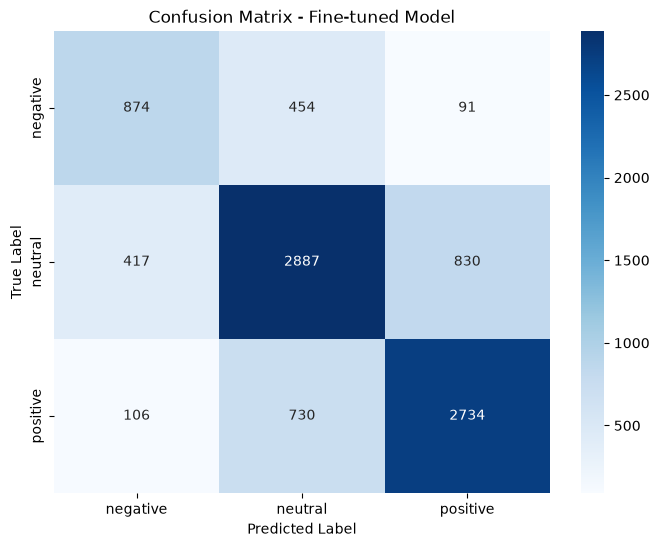

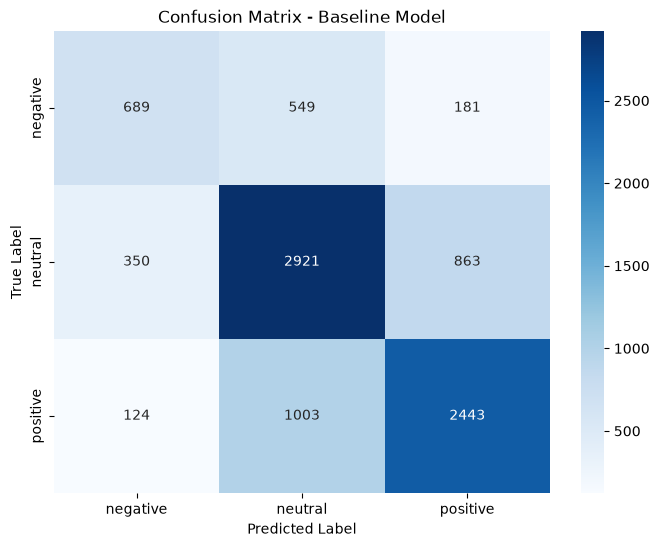

In [11]:
class_names = list(LABELS.values())
matrices = {
    "finetuned": confusion_matrix(test_labels, y_pred_ft),
    "baseline": confusion_matrix(test_labels, y_pred_base),
}
titles = {"finetuned": "Fine-tuned Model", "baseline": "Baseline Model"}

FIGURES_DIR.mkdir(exist_ok=True)
for name, cm in matrices.items():
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.title(f"Confusion Matrix - {titles[name]}")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.savefig(FIGURES_DIR / f"confusion_matrix_{name}.png")
    plt.show()

Counts are hard to compare between classes of different size: there are 1,419 negative tweets and 4,134 neutral ones. Dividing every row by its sum turns counts into shares of the true class; the diagonal becomes the recall of every class.

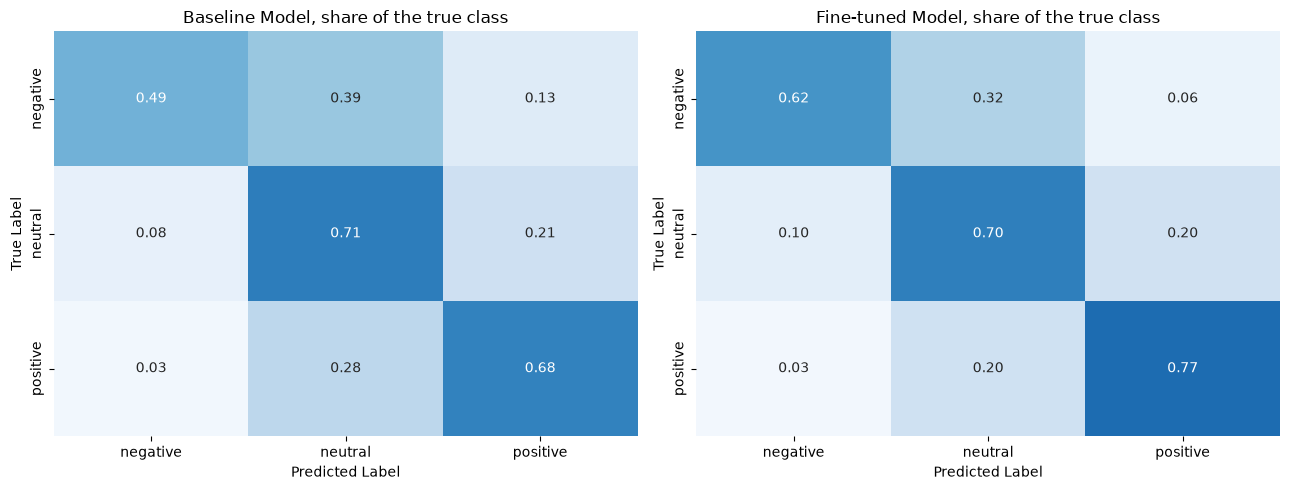

In [12]:
normalized = {
    name: cm / cm.sum(axis=1, keepdims=True) for name, cm in matrices.items()
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["baseline", "finetuned"], strict=True):
    sns.heatmap(
        normalized[name],
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"{titles[name]}, share of the true class")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
plt.tight_layout()
plt.show()

In [13]:
recall = pd.DataFrame(
    {
        "baseline": normalized["baseline"].diagonal(),
        "fine-tuned": normalized["finetuned"].diagonal(),
    },
    index=class_names,
)
recall["change"] = recall["fine-tuned"] - recall["baseline"]
recall.round(2)

,baseline,fine-tuned,change
negative,0.49,0.62,0.13
neutral,0.71,0.70,-0.01
positive,0.68,0.77,0.08


Where fine-tuning helped, class by class:

- **negative**: recall 0.49 → 0.62 (+0.13), the largest gain. The baseline sent 39% of negative tweets to neutral and 13% to positive; the fine-tuned model sends 32% and 6%. Confusing negative with positive, the worst kind of error, is halved.
- **positive**: recall 0.68 → 0.77 (+0.08), almost all of it taken from the positive → neutral errors.
- **neutral**: unchanged (0.71 → 0.70). A fifth of neutral tweets still go to positive and a tenth to negative.

So fine-tuning mostly taught the model to recognize sentiment that the baseline dismissed as neutral. What stays hard is the boundary of the neutral class, the class the EDA found to be the noisiest; the largest error cells of both models border on neutral.

## 6. Comparing the metrics

As the task asks, on the 20% split:

In [14]:
print("=== Fine-tuned Model ===")
print(
    classification_report(
        test_labels, y_pred_ft, target_names=class_names, digits=3
    )
)
f1_ft = f1_score(test_labels, y_pred_ft, average="macro")
acc_ft = accuracy_score(test_labels, y_pred_ft)

print("=== Baseline Model ===")
print(
    classification_report(
        test_labels, y_pred_base, target_names=class_names, digits=3
    )
)
f1_base = f1_score(test_labels, y_pred_base, average="macro")
acc_base = accuracy_score(test_labels, y_pred_base)

print("=== Comparison ===")
print(f"Fine-tuned F1: {f1_ft:.4f}, Accuracy: {acc_ft:.4f}")
print(f"Baseline F1: {f1_base:.4f}, Accuracy: {acc_base:.4f}")
print(f"F1 improvement: {(f1_ft - f1_base) / f1_base * 100:.2f}%")

=== Fine-tuned Model ===
              precision    recall  f1-score   support

    negative      0.626     0.616     0.621      1419
     neutral      0.709     0.698     0.704      4134
    positive      0.748     0.766     0.757      3570

    accuracy                          0.712      9123
   macro avg      0.694     0.693     0.694      9123
weighted avg      0.711     0.712     0.712      9123

=== Baseline Model ===
              precision    recall  f1-score   support

    negative      0.592     0.486     0.534      1419
     neutral      0.653     0.707     0.679      4134
    positive      0.701     0.684     0.692      3570

    accuracy                          0.663      9123
   macro avg      0.649     0.625     0.635      9123
weighted avg      0.662     0.663     0.662      9123

=== Comparison ===
Fine-tuned F1: 0.6938, Accuracy: 0.7119
Baseline F1: 0.6349, Accuracy: 0.6635
F1 improvement: 9.26%


### The official test split

The 20% split comes from the same period and topics as the training tweets. The official test split does not (US politics of 2016-2017, see `00_eda.ipynb`), so it shows how well each model carries over to new topics. Both models are the same as above, trained on the same 80% of train.

In [15]:
official_test = load_split("test")
official_texts = official_test["text"].tolist()
official_labels = official_test["label"].tolist()

y_official_ft = [
    p["prediction"]
    for p in predict_fine_tuned(
        official_texts, model_ft, tokenizer, clean_text
    )
]
y_official_base = [
    p["prediction"]
    for p in predict_baseline(
        official_texts, baseline_model, baseline_vectorizer, clean_text
    )
]


def scores(true_labels, predictions):
    return {
        "macro F1": f1_score(true_labels, predictions, average="macro"),
        "accuracy": accuracy_score(true_labels, predictions),
    }


comparison = pd.DataFrame(
    {
        "fine-tuned, 20% split": scores(test_labels, y_pred_ft),
        "baseline, 20% split": scores(test_labels, y_pred_base),
        "fine-tuned, official test": scores(official_labels, y_official_ft),
        "baseline, official test": scores(official_labels, y_official_base),
    }
).T
comparison.round(4)

,macro F1,accuracy
"fine-tuned, 20% split",0.6938,0.7119
"baseline, 20% split",0.6349,0.6635
"fine-tuned, official test",0.6773,0.6796
"baseline, official test",0.6479,0.6565


| | 20% split | official test |
|---|---|---|
| baseline macro F1 | 0.635 | 0.648 |
| fine-tuned macro F1 | 0.694 | 0.677 |
| improvement | +9.3% | +4.5% |

Fine-tuning wins everywhere, on all classes of the 20% split as well: F1 0.53 → 0.62 for negative, 0.68 → 0.70 for neutral, 0.69 → 0.76 for positive. Negative gains in both precision and recall, so the model finds more negative tweets without paying for it with false alarms.

On the official test split the gain halves. The fine-tuned model adapted to the training tweets, which helps less on new topics; the frozen baseline does not adapt and keeps the same level. A larger gain would need either data closer to the target tweets or a model pre-trained on tweets (day 1 bonus).

## 7. Saving the comparison

`results/comparison_results.txt` follows the format of the task for the 20% split and adds the official test split and the per-class F1, next to the baseline and fine-tuned results of days 4 and 5.

In [16]:
def improvement(new, old):
    return (new - old) / old * 100


f1_official_ft = comparison.loc["fine-tuned, official test", "macro F1"]
f1_official_base = comparison.loc["baseline, official test", "macro F1"]
per_class = pd.DataFrame(
    {
        "baseline": f1_score(test_labels, y_pred_base, average=None),
        "fine-tuned": f1_score(test_labels, y_pred_ft, average=None),
    },
    index=class_names,
)

lines = [
    "=== Model comparison ===",
    "",
    "Test data: 20% stratified split of the train split (random_state=42),",
    "9,123 tweets neither model was trained on",
    "",
    "Fine-tuned Model:",
    f"  F1 (macro): {f1_ft:.4f}",
    f"  Accuracy: {acc_ft:.4f}",
    "",
    "Baseline Model:",
    f"  F1 (macro): {f1_base:.4f}",
    f"  Accuracy: {acc_base:.4f}",
    "",
    f"Improvement: {improvement(f1_ft, f1_base):.2f}%",
    "",
    "F1 per class on the 20% split:",
    per_class.round(4).to_string(),
    "",
    "Official test split (12,284 tweets, other topics):",
    comparison.loc[["fine-tuned, official test", "baseline, official test"]]
    .round(4)
    .to_string(),
    f"Improvement: {improvement(f1_official_ft, f1_official_base):.2f}%",
]
(RESULTS_DIR / "comparison_results.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

=== Model comparison ===

Test data: 20% stratified split of the train split (random_state=42),
9,123 tweets neither model was trained on

Fine-tuned Model:
  F1 (macro): 0.6938
  Accuracy: 0.7119

Baseline Model:
  F1 (macro): 0.6349
  Accuracy: 0.6635

Improvement: 9.26%

F1 per class on the 20% split:
          baseline  fine-tuned
negative    0.5337      0.6207
neutral     0.6787      0.7037
positive    0.6924      0.7568

Official test split (12,284 tweets, other topics):
                           macro F1  accuracy
fine-tuned, official test    0.6773    0.6796
baseline, official test      0.6479    0.6565
Improvement: 4.54%
